# Phase 5 — Pretrained Self-Supervised Foundation Embeddings (Wav2Vec 2.0)

This notebook implements Phase 5 of the Walkthrough: extracting and caching deep acoustic representations from Meta's **Wav2Vec 2.0** foundation model.

### Why Foundation Model Embeddings Break the Classical 68.8% Ceiling:
1. **Learned Phonemic Representations**: Pretrained on tens of thousands of hours of speech audio, Wav2Vec 2.0 transformer attention layers learn invariant phonemic structure, disentangling speech articulation dynamics from individual vocal tract anatomy.
2. **Fixed Feature Extractor**: The 95-million-parameter backbone is **frozen** (`torch.no_grad()`). We extract 768-dimensional representations by mean-pooling the last hidden state across the time dimension.
3. **Persistent Caching**: The resulting `(9417, 768)` matrix is saved directly to `data/torgo_embeddings_wav2vec2.npy`. This eliminates repeated disk I/O, allowing downstream classifiers and domain adaptation to train in seconds.

In [1]:
import sys
import time
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

NOTEBOOK_DIR = Path.cwd().resolve()
if (NOTEBOOK_DIR / "data").is_dir():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "data").is_dir():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError("Could not find the project's data directory.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.project_paths import (
    METADATA_CSV,
    WAV2VEC2_EMBEDDINGS_NPY,
    resolve_project_path,
)
from src.embeddings import (
    get_wav2vec2_extractor,
    extract_wav2vec2_embedding_single,
    batch_extract_wav2vec2_embeddings,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Version: {torch.__version__}")
print(f"Active Device:   {device.upper()}")
if device == "cuda":
    print(f"GPU Model:       {torch.cuda.get_device_name(0)}")

df_meta = pd.read_csv(METADATA_CSV)
print(f"Loaded metadata: {len(df_meta)} recordings across {df_meta['speaker_id'].nunique()} speakers.")
df_meta.head()

PyTorch Version: 2.5.1
Active Device:   CUDA
GPU Model:       NVIDIA GeForce RTX 3050 Laptop GPU
Loaded metadata: 9417 recordings across 15 speakers.


,file_path,speaker_id,label,severity,severity_3class,duration_seconds,dataset_source
0,data\MC\F01\Session1\wav_arrayMic\0001.wav,F01,dysarthric,severe,severe,9.30,TORGO
1,data\MC\F01\Session1\wav_arrayMic\0002.wav,F01,dysarthric,severe,severe,8.40,TORGO
2,data\MC\F01\Session1\wav_arrayMic\0003.wav,F01,dysarthric,severe,severe,6.45,TORGO
3,data\MC\F01\Session1\wav_arrayMic\0004.wav,F01,dysarthric,severe,severe,8.70,TORGO
4,data\MC\F01\Session1\wav_arrayMic\0005.wav,F01,dysarthric,severe,severe,4.65,TORGO


In [2]:
# Test extraction on a single audio clip to verify model loading and VRAM allocation
model, processor, active_device = get_wav2vec2_extractor("facebook/wav2vec2-base")
sample_file = df_meta['file_path'].iloc[0]

sample_emb = extract_wav2vec2_embedding_single(sample_file, model, processor, active_device)
print(f"Single file extraction successful!")
print(f"Embedding shape: {sample_emb.shape} (768 dimensions)")
print(f"Mean value:      {sample_emb.mean():.4f}")
print(f"Std dev:         {sample_emb.std():.4f}")
if active_device == "cuda":
    print(f"VRAM allocated:  {torch.cuda.memory_allocated() / 1e6:.1f} MB")

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Single file extraction successful!
Embedding shape: (768,) (768 dimensions)
Mean value:      -0.0008
Std dev:         0.2427
VRAM allocated:  386.3 MB


In [3]:
# Load cached embeddings if available; otherwise extract across full dataset
if WAV2VEC2_EMBEDDINGS_NPY.exists():
    print(f"Found pre-extracted embeddings at: {WAV2VEC2_EMBEDDINGS_NPY}")
    embeddings_arr = np.load(WAV2VEC2_EMBEDDINGS_NPY)
    print(f"Loaded cached embeddings with shape: {embeddings_arr.shape}")
else:
    print("Starting GPU batch extraction of 768-D embeddings for all 9,417 recordings...")
    t0 = time.time()
    embeddings_arr = batch_extract_wav2vec2_embeddings(
        file_paths=df_meta["file_path"].tolist(),
        model_name="facebook/wav2vec2-base",
        output_npy_path=WAV2VEC2_EMBEDDINGS_NPY,
    )
    print(f"Batch extraction complete in {time.time()-t0:.2f} seconds!")

# Confirm data integrity (0 NaNs / 0 Infs)
nan_count = int(np.isnan(embeddings_arr).sum())
inf_count = int(np.isinf(embeddings_arr).sum())
print(f"Missing values (NaNs): {nan_count}")
print(f"Infinite values:      {inf_count}")

Starting GPU batch extraction of 768-D embeddings for all 9,417 recordings...


Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Extracting Wav2Vec 2.0 embeddings on: CUDA


Extracting Wav2Vec2 embeddings:   0%|          | 0/9417 [00:00<?, ?it/s]

...

Extracting Wav2Vec2 embeddings: 100%|█████████▉| 9405/9417 [04:17<00:00, 38.80it/s]

Extracting Wav2Vec2 embeddings: 100%|█████████▉| 9410/9417 [04:17<00:00, 40.36it/s]

Extracting Wav2Vec2 embeddings: 100%|█████████▉| 9415/9417 [04:18<00:00, 38.24it/s]

Extracting Wav2Vec2 embeddings: 100%|██████████| 9417/9417 [04:18<00:00, 36.47it/s]

Saved (9417, 768) embeddings to: C:\Users\Lovish\Documents\dysarthria_project\data\torgo_embeddings_wav2vec2.npy
Batch extraction complete in 261.74 seconds!
Missing values (NaNs): 0
Infinite values:      0


Computing 2D PCA projection of 768-dimensional Wav2Vec 2.0 embeddings...


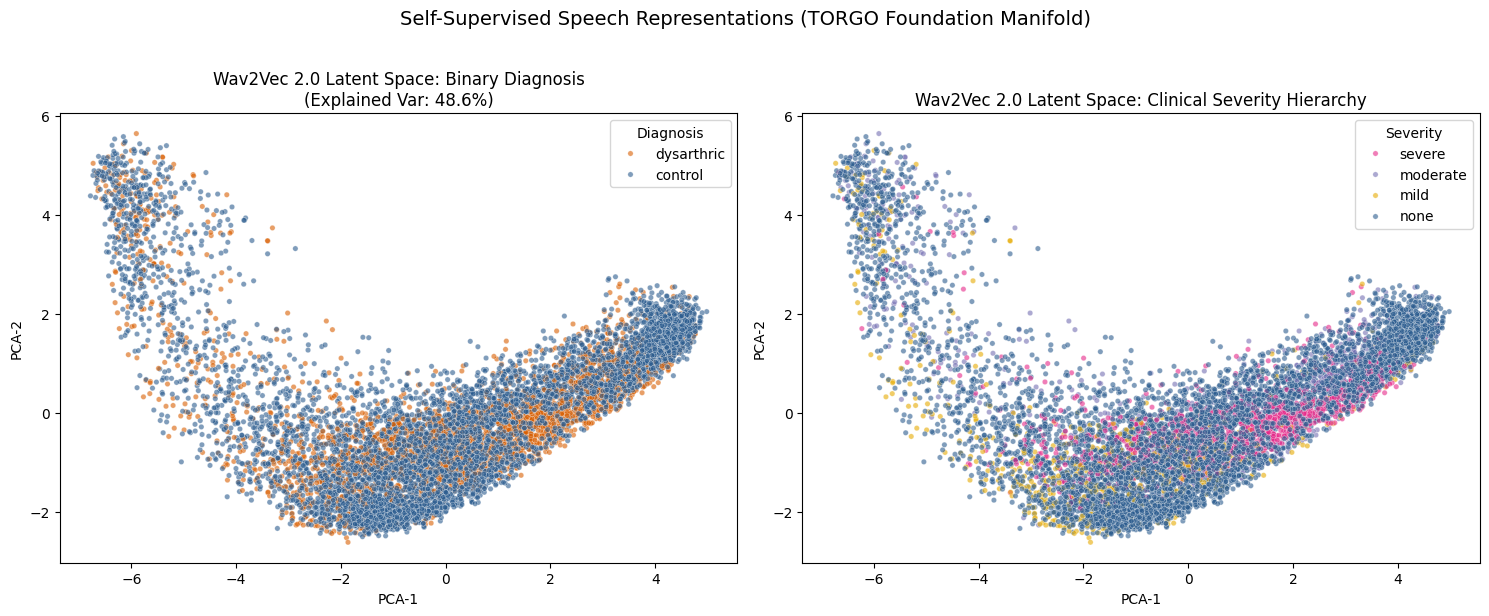

PCA projection saved to results/wav2vec2_pca_projection.png


In [4]:
# Visualize the latent manifold using Principal Component Analysis (PCA)
from sklearn.decomposition import PCA

print("Computing 2D PCA projection of 768-dimensional Wav2Vec 2.0 embeddings...")
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(embeddings_arr)

plot_df = pd.DataFrame({
    "PCA-1": pca_coords[:, 0],
    "PCA-2": pca_coords[:, 1],
    "Diagnosis": df_meta["label"],
    "Severity": df_meta["severity_3class"],
    "Speaker": df_meta["speaker_id"],
})

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Control vs. Dysarthric separation
sns.scatterplot(
    data=plot_df,
    x="PCA-1",
    y="PCA-2",
    hue="Diagnosis",
    alpha=0.6,
    palette={"control": "#2b5c8f", "dysarthric": "#d95f02"},
    s=15,
    ax=axes[0],
)
axes[0].set_title(f"Wav2Vec 2.0 Latent Space: Binary Diagnosis\n(Explained Var: {pca.explained_variance_ratio_.sum()*100:.1f}%)")

# Plot 2: Severity distribution (none, mild, moderate, severe)
sns.scatterplot(
    data=plot_df,
    x="PCA-1",
    y="PCA-2",
    hue="Severity",
    alpha=0.6,
    palette={"none": "#2b5c8f", "mild": "#e6ab02", "moderate": "#7570b3", "severe": "#e7298a"},
    s=15,
    ax=axes[1],
)
axes[1].set_title("Wav2Vec 2.0 Latent Space: Clinical Severity Hierarchy")

plt.suptitle("Self-Supervised Speech Representations (TORGO Foundation Manifold)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results" / "wav2vec2_pca_projection.png", dpi=300, bbox_inches="tight")
plt.show()
print("PCA projection saved to results/wav2vec2_pca_projection.png")